### Import

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score  # Or mean_squared_error, r2_score

warnings.filterwarnings('ignore')

### Dataset
A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification method[https://archive.ics.uci.edu/dataset/53/iris]. 

In [73]:
cols = ["sepal_length", "sepal_width", "petal_length", "petal_width", "class"]
df = pd.read_csv("iris.data", names=cols)
df.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [74]:
df["class"] = df["class"].str.lower()

print(df["class"].unique())

<StringArray>
['iris-setosa', 'iris-versicolor', 'iris-virginica']
Length: 3, dtype: str


In [75]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None


#### Probabilty Density

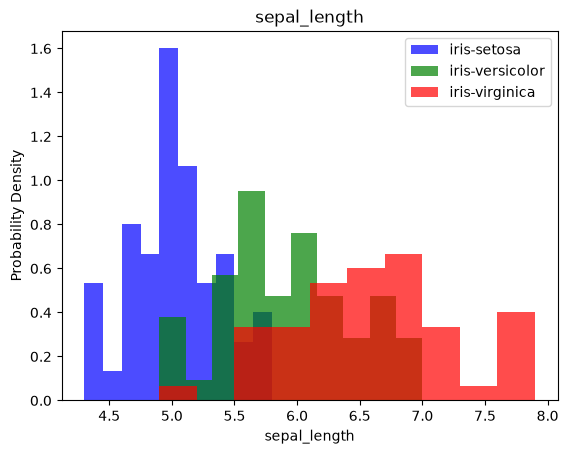

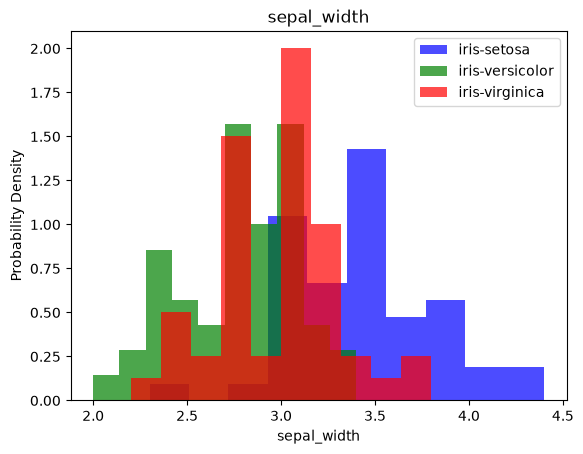

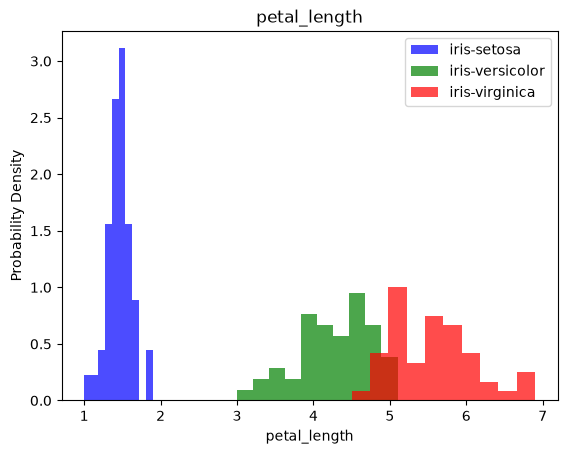

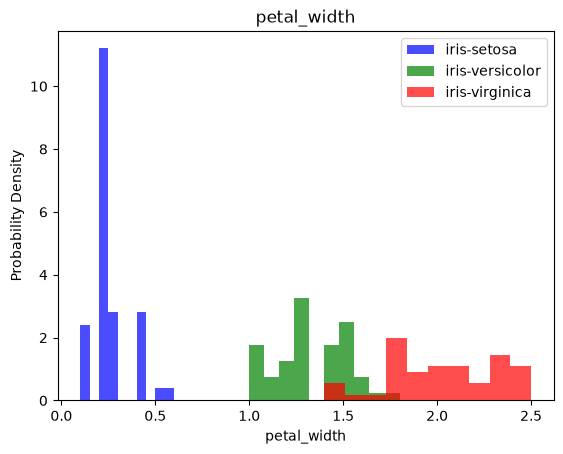

In [76]:
for label in cols[:-1]:
  plt.hist(df[df["class"]=="iris-setosa"][label], color='blue', label='iris-setosa', alpha=0.7, density=True)
  plt.hist(df[df["class"]=="iris-versicolor"][label], color='green', label='iris-versicolor', alpha=0.7, density=True)
  plt.hist(df[df["class"]=="iris-virginica"][label], color='red', label='iris-virginica', alpha=0.7, density=True)
  plt.title(label)
  plt.ylabel("Probability Density")
  plt.xlabel(label)
  plt.legend()
  plt.show()

#### Frequency

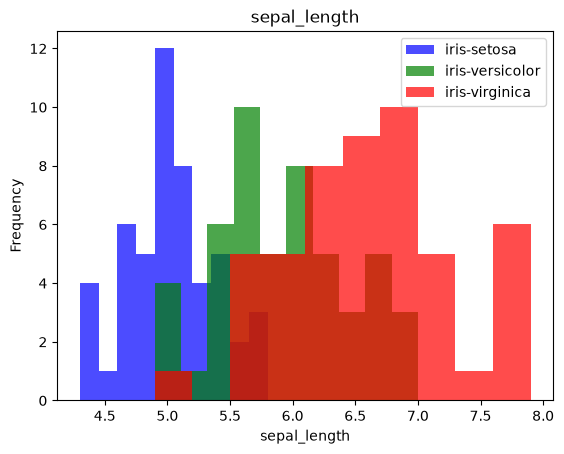

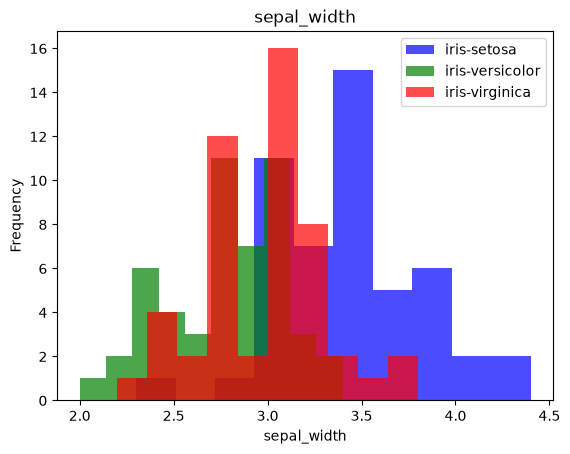

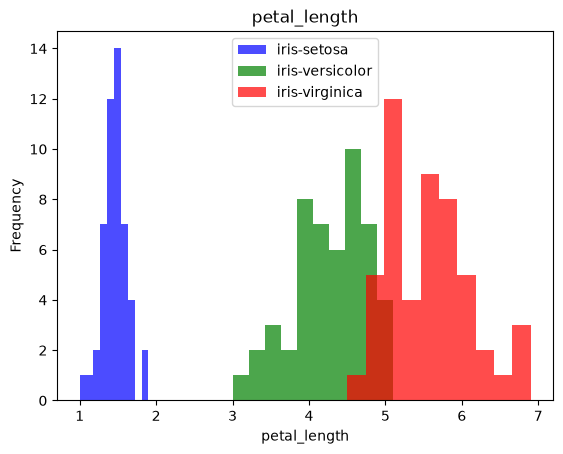

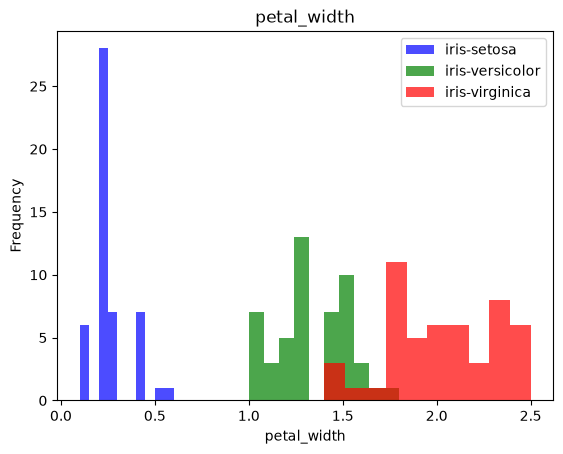

In [77]:
for label in cols[:-1]:
  plt.hist(df[df["class"]=="iris-setosa"][label], color='blue', label='iris-setosa', alpha=0.7, density=False)
  plt.hist(df[df["class"]=="iris-versicolor"][label], color='green', label='iris-versicolor', alpha=0.7, density=False)
  plt.hist(df[df["class"]=="iris-virginica"][label], color='red', label='iris-virginica', alpha=0.7, density=False)
  plt.title(label)
  plt.ylabel("Frequency")
  plt.xlabel(label)
  plt.legend()
  plt.show()

### Random Forest

In [78]:
# 1. Feature / Target separation
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 2. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

# 3. Model Initialization
rf_model = RandomForestClassifier(
    n_estimators=100,      # Number of decision trees
    max_depth=None,        # Maximum depth of each tree
    min_samples_split=2,   # Minimum samples required to split an internal node
    min_samples_leaf=1,    # Minimum samples required at a leaf node
    random_state=42,
    n_jobs=-1              # Use all available CPU cores
)

# 4. Train
rf_model.fit(X_train, y_train)

# 5. Predict
y_pred = rf_model.predict(X_test)

# 6. Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.0

Classification Report:
                  precision    recall  f1-score   support

    iris-setosa       1.00      1.00      1.00        19
iris-versicolor       1.00      1.00      1.00        13
 iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



### kNN

In [79]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [80]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['iris-setosa','iris-versicolor','iris-virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [81]:
y_pred = knn_model.predict(X_test)

In [82]:
print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    iris-setosa       1.00      1.00      1.00        19
iris-versicolor       1.00      1.00      1.00        13
 iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



### Naive Bayes

In [83]:
from sklearn.naive_bayes import GaussianNB

In [84]:
nb_model = GaussianNB()
nb_model = nb_model.fit(X_train, y_train)

In [85]:
y_pred = nb_model.predict(X_test)
print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    iris-setosa       1.00      1.00      1.00        19
iris-versicolor       1.00      0.92      0.96        13
 iris-virginica       0.93      1.00      0.96        13

       accuracy                           0.98        45
      macro avg       0.98      0.97      0.97        45
   weighted avg       0.98      0.98      0.98        45



### Log Regression

In [86]:
from sklearn.linear_model import LogisticRegression

In [87]:
lg_model = LogisticRegression()
lg_model = lg_model.fit(X_train, y_train)

In [88]:
y_pred = lg_model.predict(X_test)
print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    iris-setosa       1.00      1.00      1.00        19
iris-versicolor       1.00      1.00      1.00        13
 iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



### SVM

In [89]:
from sklearn.svm import SVC

In [90]:
svm_model = SVC()
svm_model = svm_model.fit(X_train, y_train)

In [91]:
y_pred = svm_model.predict(X_test)
print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    iris-setosa       1.00      1.00      1.00        19
iris-versicolor       1.00      1.00      1.00        13
 iris-virginica       1.00      1.00      1.00        13

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45

